# Exploratory Data Analysis of Google FLEURS: Egyptian Arabic (`ar_eg`)
### Training split | Audio, transcripts, speakers, linguistic patterns, and data quality

**Purpose.** This notebook performs a reproducible exploratory analysis of the Google FLEURS Egyptian Arabic training split. It is designed to support general dataset understanding, Arabic ASR research, and preparation for Whisper fine-tuning.

**Analysis strategy**
- Download the complete `train` split and analyze its metadata and transcripts.
- Decode audio only for a configurable representative sample (default: 500 recordings).
- Use random sampling by default, with optional speaker-stratified sampling when speaker metadata is available.
- Preserve the original transcript. Create a separate lightly normalized transcript for analysis.
- Explain the results after each major section and save plots, tables, and a Markdown report.
- Generate a standalone PDF report and provide a workflow for exporting the executed notebook itself to PDF.

> **Important:** This notebook does not assume that every metadata field is present. It inspects the actual dataset schema and conditionally runs speaker- or gender-specific analyses. Any missing field is reported rather than fabricated.

## 0. Configuration

Run this cell first. Change the sample size, sampling strategy, and output location here. For Google Drive output, mount Drive when prompted.

In [1]:
# Core configuration
DATASET_ID = "google/fleurs"
CONFIG_NAME = "ar_eg"
SPLIT = "train"

RANDOM_SEED = 42
AUDIO_SAMPLE_SIZE = 500
AUDIO_SAMPLING_STRATEGY = "random"  # "random", "stratified", or "random_with_stratified_option"

# Output configuration
SAVE_TO_GOOGLE_DRIVE = True
DRIVE_OUTPUT_DIR = "/content/drive/MyDrive/FLEURS_ar_eg_EDA"
LOCAL_OUTPUT_DIR = "/content/fleurs_ar_eg_eda_outputs"

# Plot configuration
FIGURE_DPI = 150
TOP_N_WORDS = 25
TOP_N_CHARACTERS = 30

# Audio-analysis safety limits
MAX_AUDIO_SECONDS_FOR_WAVEFORM = 20
N_SPECTROGRAM_EXAMPLES = 3

print("Configuration loaded.")

Configuration loaded.


## 1. Install and import dependencies

The notebook uses Hugging Face `datasets`, pandas, NumPy, Matplotlib, Seaborn, librosa, SoundFile, and ReportLab. The installation cell is intended for a fresh Google Colab runtime.

In [2]:
%pip -q install -U datasets[audio] librosa soundfile seaborn scipy reportlab nbconvert

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [3]:
%pip install -q jedi "decorator>=4.0.2,<5.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
librosa 1.0.0 requires decorator>=5.2.1, but you have decorator 4.4.2 which is incompatible.


In [22]:
import os
import re
import json
import math
import shutil
import random
import warnings
import textwrap
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Audio, display, Markdown
from datasets import load_dataset, Audio as HFAudio
import datasets

import librosa
import librosa.display
import soundfile as sf

from scipy.stats import spearmanr, pearsonr

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 160)

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Python and analysis libraries imported.")

Python and analysis libraries imported.


## 2. Prepare output directory and mount Google Drive

In [5]:
if SAVE_TO_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUTPUT_DIR = Path(DRIVE_OUTPUT_DIR)
    except Exception as exc:
        print(f"Google Drive could not be mounted ({exc}). Falling back to local storage.")
        OUTPUT_DIR = Path(LOCAL_OUTPUT_DIR)
else:
    OUTPUT_DIR = Path(LOCAL_OUTPUT_DIR)

PLOTS_DIR = OUTPUT_DIR / "plots"
TABLES_DIR = OUTPUT_DIR / "tables"
REPORT_DIR = OUTPUT_DIR / "reports"

for folder in [OUTPUT_DIR, PLOTS_DIR, TABLES_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(f"Outputs will be saved to: {OUTPUT_DIR}")

Mounted at /content/drive
Outputs will be saved to: /content/drive/MyDrive/FLEURS_ar_eg_EDA


## 3. Download the complete training split

The dataset is loaded from the Hugging Face Datasets Hub. The complete split is retained for metadata and transcript analysis. Audio decoding is deliberately deferred until the representative audio sample is selected.

In [6]:
dataset = load_dataset(DATASET_ID, CONFIG_NAME, split=SPLIT)

print(dataset)
print("\nNumber of training examples:", len(dataset))
print("\nDataset features:")
for feature_name, feature in dataset.features.items():
    print(f"- {feature_name}: {feature}")

README.md:   0%|          | 0.00/386k [00:00<?, ?B/s]

parquet-data/ar_eg/train-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B / 1.38GB            

parquet-data/ar_eg/train-00000-of-00001.(…): downloading bytes:           |  0.00B            

parquet-data/ar_eg/validation-00000-of-0(…): reconstructing file:   0%|          |  0.00B /  200MB            

parquet-data/ar_eg/validation-00000-of-0(…): downloading bytes:           |  0.00B            

parquet-data/ar_eg/test-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B /  297MB            

parquet-data/ar_eg/test-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2104 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/295 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/428 [00:00<?, ? examples/s]

Dataset({
    features: ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id'],
    num_rows: 2104
})

Number of training examples: 2104

Dataset features:
- id: Value('int32')
- num_samples: Value('int32')
- path: Value('string')
- audio: Audio(sampling_rate=16000, decode=True, num_channels=None, stream_index=None)
- transcription: Value('string')
- raw_transcription: Value('string')
- gender: ClassLabel(names=['male', 'female', 'other'])
- lang_id: ClassLabel(names=['af_za', 'am_et', 'ar_eg', 'as_in', 'ast_es', 'az_az', 'be_by', 'bg_bg', 'bn_in', 'bs_ba', 'ca_es', 'ceb_ph', 'ckb_iq', 'cmn_hans_cn', 'cs_cz', 'cy_gb', 'da_dk', 'de_de', 'el_gr', 'en_us', 'es_419', 'et_ee', 'fa_ir', 'ff_sn', 'fi_fi', 'fil_ph', 'fr_fr', 'ga_ie', 'gl_es', 'gu_in', 'ha_ng', 'he_il', 'hi_in', 'hr_hr', 'hu_hu', 'hy_am', 'id_id', 'ig_ng', 'is_is', 'it_it', 'ja_jp', 'jv_id', 'ka_ge', 'kam_ke', 'kea_cv', 'kk_kz', 'km_kh', 'kn_in', 'ko_kr', '

## 4. Build a metadata table without decoding the audio

We remove the audio column before converting the dataset to pandas. This keeps the full-split metadata and transcript analysis lightweight and avoids decoding every recording.

In [7]:
all_columns = list(dataset.column_names)
audio_column = "audio" if "audio" in all_columns else None

metadata_columns = [c for c in all_columns if c != audio_column]
metadata_dataset = dataset.remove_columns(audio_column) if audio_column else dataset
df = metadata_dataset.to_pandas()

print("Metadata table shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype"))

Metadata table shape: (2104, 9)


,id,num_samples,path,transcription,raw_transcription,gender,lang_id,language,lang_group_id
0,351,187200,/root/.cache/huggingface/datasets/downloads/extracted/2ce2b3ac8c2663ef58b55846e287a9f39de15427544246574cb367e01d7c9d32/10002899498199807056.wav,وعلى الرغم من ذلك فإنها معضلة من الصعب حلها وستستغرق سنين طوال قبل أن نشهد بناء مفاعلات اندماج ذات نفع,وعلى الرغم من ذلك، فإنها معضلة من الصعب حلها وستستغرق سنين طوال قبل أن نشهد بناء مفاعلات اندماج ذات نفع.,0,2,Arabic,2
1,721,243840,/root/.cache/huggingface/datasets/downloads/extracted/2ce2b3ac8c2663ef58b55846e287a9f39de15427544246574cb367e01d7c9d32/10019242954322166768.wav,بجانب الشواطئ ذات الرمال البيضاء والمناظر الطبيعية الجبلية تعد البلاد موطنًا لأقدم مدينة أوروبية في الأمريكتين وهي الآن جزء من سانتو دومينغو,بجانب الشواطئ ذات الرمال البيضاء والمناظر الطبيعية الجبلية، تعد البلاد موطنًا لأقدم مدينة أوروبية في الأمريكتين، وهي الآن جزء من سانتو دومينغو.,1,2,Arabic,2
2,376,138240,/root/.cache/huggingface/datasets/downloads/extracted/2ce2b3ac8c2663ef58b55846e287a9f39de15427544246574cb367e01d7c9d32/10055519759885576331.wav,ليس للشمس قشرة يمكنك الوقوف عليها مثل الأرض تتكون الشمس بالكامل من الغازات والنار والبلازما,ليس للشمس قشرة يمكنك الوقوف عليها مثل الأرض. تتكون الشمس بالكامل من الغازات، والنار، والبلازما.,1,2,Arabic,2
3,1362,264960,/root/.cache/huggingface/datasets/downloads/extracted/2ce2b3ac8c2663ef58b55846e287a9f39de15427544246574cb367e01d7c9d32/10058986041070511183.wav,تحبّ حيوانات النّمر القزم أكل الحيوانات الصغيرة فهي تصطاد القرود والثعابين والقوارض والطّيور إذا استطاعت ذلك تقريباً جميع الحيوانات التي يصطادها النّمر القز...,تحبّ حيوانات النّمر القزم أكل الحيوانات الصغيرة، فهي تصطاد القرود والثعابين والقوارض والطّيور إذا استطاعت ذلك. تقريباً جميع الحيوانات التي يصطادها النّمر ال...,0,2,Arabic,2
4,308,58560,/root/.cache/huggingface/datasets/downloads/extracted/2ce2b3ac8c2663ef58b55846e287a9f39de15427544246574cb367e01d7c9d32/10065663880468556411.wav,مات في أوساكا يوم الثلاثاء,مات في أوساكا يوم الثلاثاء.,1,2,Arabic,2


,dtype
id,int32
num_samples,int32
path,object
transcription,object
raw_transcription,object
gender,int64
lang_id,int64
language,object
lang_group_id,int64


## 5. Dataset overview

This section describes the number of records, available columns, data types, missing values, and basic metadata characteristics. Counts are calculated from the downloaded split rather than copied from an external description.

In [8]:
overview = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "missing_count": [int(df[c].isna().sum()) for c in df.columns],
    "missing_percent": [float(df[c].isna().mean() * 100) for c in df.columns],
    "unique_non_null": [int(df[c].nunique(dropna=True)) for c in df.columns],
})
display(overview)
overview.to_csv(TABLES_DIR / "dataset_column_overview.csv", index=False)

print(f"Rows: {len(df):,}")
print(f"Metadata columns: {len(df.columns)}")
print(f"Duplicate complete metadata rows: {int(df.duplicated().sum()):,}")

,column,dtype,missing_count,missing_percent,unique_non_null
0,id,int32,0,0.0,1275
1,num_samples,int32,0,0.0,297
2,path,object,0,0.0,2104
3,transcription,object,0,0.0,1275
4,raw_transcription,object,0,0.0,1275
5,gender,int64,0,0.0,2
6,lang_id,int64,0,0.0,1
7,language,object,0,0.0,1
8,lang_group_id,int64,0,0.0,1


Rows: 2,104
Metadata columns: 9
Duplicate complete metadata rows: 0


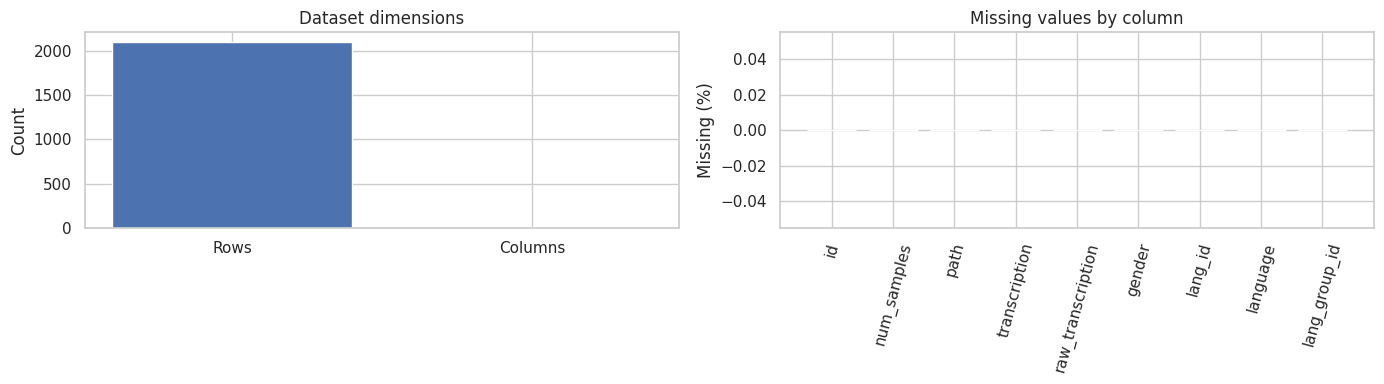

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(["Rows", "Columns"], [len(df), len(df.columns)])
axes[0].set_title("Dataset dimensions")
axes[0].set_ylabel("Count")

missing = overview.sort_values("missing_percent", ascending=False)
axes[1].bar(missing["column"], missing["missing_percent"])
axes[1].set_title("Missing values by column")
axes[1].set_ylabel("Missing (%)")
axes[1].tick_params(axis="x", rotation=75)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "dataset_overview.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()

## 6. Identify transcript and speaker fields

FLEURS releases can expose transcript fields under different names. The next cell detects common names and prints the chosen fields. If automatic detection fails, set the relevant variable manually.

In [ ]:
def first_existing(candidates, columns):
    return next((name for name in candidates if name in columns), None)

TRANSCRIPT_COL = first_existing(
    ["transcription", "raw_transcription", "sentence", "text"],
    df.columns
)
RAW_TRANSCRIPT_COL = first_existing(
    ["raw_transcription", "transcription", "sentence", "text"],
    df.columns
)
SPEAKER_COL = first_existing(["speaker_id", "speaker", "client_id"], df.columns)
GENDER_COL = first_existing(["gender", "speaker_gender", "sex"], df.columns)
ID_COL = first_existing(["id", "utterance_id", "sentence_id"], df.columns)

print("Transcript column:", TRANSCRIPT_COL)
print("Raw transcript column:", RAW_TRANSCRIPT_COL)
print("Speaker column:", SPEAKER_COL)
print("Gender column:", GENDER_COL)
print("Record identifier column:", ID_COL)

if TRANSCRIPT_COL is None:
    raise ValueError(
        "Could not detect a transcript column. Inspect df.columns and set TRANSCRIPT_COL manually."
    )

Transcript column: transcription
Raw transcript column: raw_transcription
Speaker column: None
Gender column: gender
Record identifier column: id


## 7. Transcript preparation and Arabic text normalization

The original dataset transcript remains unchanged. A separate lightly normalized column is created for analysis. The normalization below:
- converts missing values to empty strings for safe processing;
- removes tatweel;
- removes Arabic diacritics (harakat);
- standardizes common Alef variants;
- standardizes Alef Maqsura to Ya;
- normalizes whitespace.

This is an **analysis convenience**, not a claim that this is the correct normalization target for every ASR evaluation protocol. Keep the original text for reference and evaluation.

In [11]:
ARABIC_DIACRITICS_RE = re.compile(
    r"[\u0610-\u061A\u064B-\u065F\u0670\u06D6-\u06ED]"
)

def normalize_arabic_light(text):
    if pd.isna(text):
        return ""
    text = str(text)
    text = text.replace("ـ", "")  # tatweel
    text = ARABIC_DIACRITICS_RE.sub("", text)
    text = re.sub(r"[إأآٱ]", "ا", text)
    text = text.replace("ى", "ي")
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["transcript_original"] = df[TRANSCRIPT_COL].fillna("").astype(str)
df["transcript_normalized"] = df["transcript_original"].map(normalize_arabic_light)

# Tokenization is intentionally simple and transparent.
# It separates on whitespace; punctuation is analyzed separately below.
df["tokens"] = df["transcript_normalized"].map(
    lambda value: value.split() if value else []
)
df["word_count"] = df["tokens"].map(len)
df["character_count"] = df["transcript_original"].map(len)
df["normalized_character_count"] = df["transcript_normalized"].map(len)
df["unique_word_count"] = df["tokens"].map(lambda tokens: len(set(tokens)))

display(df[["transcript_original", "transcript_normalized", "word_count"]].head(10))

,transcript_original,transcript_normalized,word_count
0,وعلى الرغم من ذلك فإنها معضلة من الصعب حلها وستستغرق سنين طوال قبل أن نشهد بناء مفاعلات اندماج ذات نفع,وعلي الرغم من ذلك فانها معضلة من الصعب حلها وستستغرق سنين طوال قبل ان نشهد بناء مفاعلات اندماج ذات نفع,20
1,بجانب الشواطئ ذات الرمال البيضاء والمناظر الطبيعية الجبلية تعد البلاد موطنًا لأقدم مدينة أوروبية في الأمريكتين وهي الآن جزء من سانتو دومينغو,بجانب الشواطئ ذات الرمال البيضاء والمناظر الطبيعية الجبلية تعد البلاد موطنا لاقدم مدينة اوروبية في الامريكتين وهي الان جزء من سانتو دومينغو,22
2,ليس للشمس قشرة يمكنك الوقوف عليها مثل الأرض تتكون الشمس بالكامل من الغازات والنار والبلازما,ليس للشمس قشرة يمكنك الوقوف عليها مثل الارض تتكون الشمس بالكامل من الغازات والنار والبلازما,15
3,تحبّ حيوانات النّمر القزم أكل الحيوانات الصغيرة فهي تصطاد القرود والثعابين والقوارض والطّيور إذا استطاعت ذلك تقريباً جميع الحيوانات التي يصطادها النّمر القز...,تحب حيوانات النمر القزم اكل الحيوانات الصغيرة فهي تصطاد القرود والثعابين والقوارض والطيور اذا استطاعت ذلك تقريبا جميع الحيوانات التي يصطادها النمر القزم تصغ...,25
4,مات في أوساكا يوم الثلاثاء,مات في اوساكا يوم الثلاثاء,5
5,استخدم في ملاحظاته كلماتٍ اعتبرها بعض الآباء مسيئة وقيل إنه استخدم ألفاظاً نابيةً في الصف الدراسي,استخدم في ملاحظاته كلمات اعتبرها بعض الاباء مسيئة وقيل انه استخدم الفاظا نابية في الصف الدراسي,16
6,على مر القرون بنى الناس الشرفات بعناية على المناظر الطبيعية الوعرة شديدة الانحدار لتصل بينها وبين المنحدرات المُطلّة على البحر,علي مر القرون بني الناس الشرفات بعناية علي المناظر الطبيعية الوعرة شديدة الانحدار لتصل بينها وبين المنحدرات المطلة علي البحر,20
7,"كانت قوّة الهجوم الرئيسيّة المكوّنة من 2,400 رجلاً ستعبر النهر الواقع على بعد تسعة أميال شمال ترينتون ثم تنقسم إلى مجموعتين الأولى بقيادة غرين والثانية بقيا...","كانت قوة الهجوم الرئيسية المكونة من 2,400 رجلا ستعبر النهر الواقع علي بعد تسعة اميال شمال ترينتون ثم تنقسم الي مجموعتين الاولي بقيادة غرين والثانية بقيادة س...",33
8,لسوء الحظ من المرجح أن يتم قطع حدود قرص dvd عند إنشاؤه وإذا كان الفيديو يحتوي على ترجمات قريبة جداً من الجزء السفلي فلن يتم عرضها بالكامل,لسوء الحظ من المرجح ان يتم قطع حدود قرص dvd عند انشاؤه واذا كان الفيديو يحتوي علي ترجمات قريبة جدا من الجزء السفلي فلن يتم عرضها بالكامل,27
9,قال كوستيلو إنه عندما يصبح توليد الطاقة النووية مجدياً من الناحية الاقتصادية يجب على أستراليا أن السعي لاستخدامها,قال كوستيلو انه عندما يصبح توليد الطاقة النووية مجديا من الناحية الاقتصادية يجب علي استراليا ان السعي لاستخدامها,18


## 8. Transcript length and text statistics

We inspect word counts, character counts, unique-word counts, and transcript-length distributions across the entire training split.

,count,mean,std,min,5%,25%,50%,75%,95%,max
word_count,2104.0,18.138783,6.502038,5.0,9.0,13.0,17.0,22.00,30.00,55.0
character_count,2104.0,104.499049,38.039647,24.0,52.0,78.0,100.0,127.00,174.85,301.0
normalized_character_count,2104.0,103.283270,37.752788,24.0,50.0,77.0,100.0,125.25,173.85,301.0
unique_word_count,2104.0,17.233840,5.834659,5.0,9.0,13.0,17.0,21.00,28.00,46.0


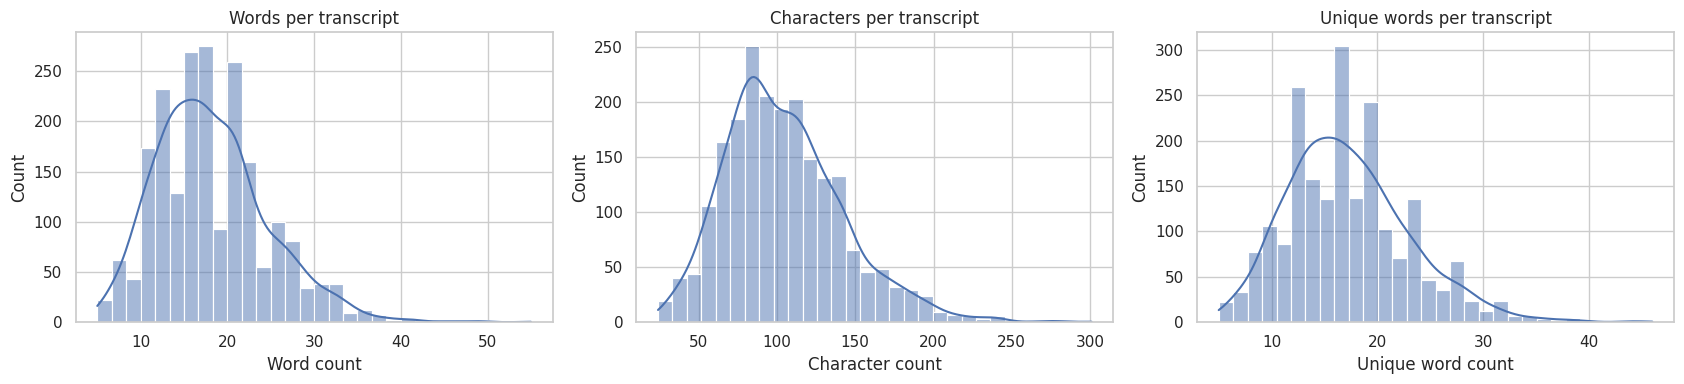

In [12]:
text_summary = df[["word_count", "character_count", "normalized_character_count", "unique_word_count"]].describe(
    percentiles=[.05, .25, .5, .75, .95]
).T
display(text_summary)
text_summary.to_csv(TABLES_DIR / "transcript_length_summary.csv")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(df["word_count"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Words per transcript")
axes[0].set_xlabel("Word count")

sns.histplot(df["character_count"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Characters per transcript")
axes[1].set_xlabel("Character count")

sns.histplot(df["unique_word_count"], bins=30, kde=True, ax=axes[2])
axes[2].set_title("Unique words per transcript")
axes[2].set_xlabel("Unique word count")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "transcript_length_distributions.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()

## 9. Vocabulary analysis

The vocabulary analysis is based on whitespace-tokenized, lightly normalized transcripts. This is useful for exploratory frequency analysis, but it is not a full morphological analysis of Arabic. Clitics and affixes may remain attached to words.

,metric,value
0,Total tokens,38164.000000
1,Vocabulary size,9518.000000
2,Type-token ratio,0.249397
3,Mean words per transcript,18.138783


,word,frequency
0,في,1464
1,من,1242
2,علي,760
3,ان,512
4,الي,452
5,او,321
6,ما,210
7,قد,165
8,التي,163
9,عن,163


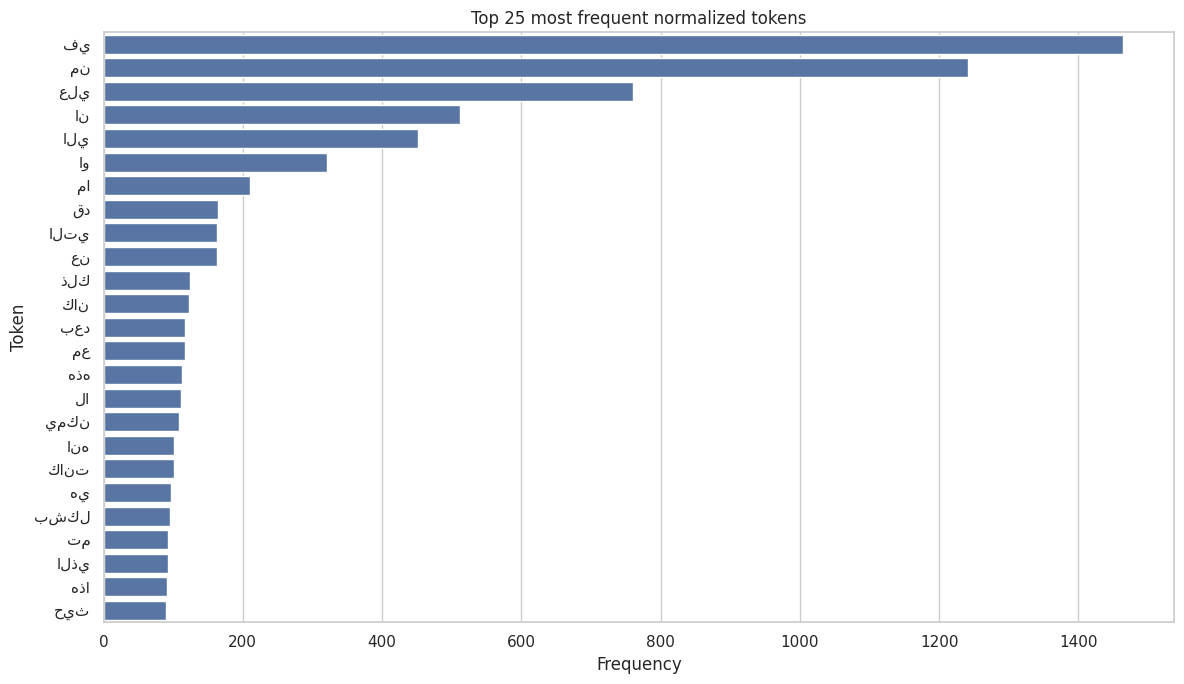

In [13]:
all_tokens = [token for tokens in df["tokens"] for token in tokens]
word_counter = Counter(all_tokens)
vocabulary_size = len(word_counter)

vocab_summary = pd.DataFrame([
    {"metric": "Total tokens", "value": len(all_tokens)},
    {"metric": "Vocabulary size", "value": vocabulary_size},
    {"metric": "Type-token ratio", "value": vocabulary_size / len(all_tokens) if all_tokens else np.nan},
    {"metric": "Mean words per transcript", "value": df["word_count"].mean()},
])
display(vocab_summary)
vocab_summary.to_csv(TABLES_DIR / "vocabulary_summary.csv", index=False)

top_words = pd.DataFrame(word_counter.most_common(TOP_N_WORDS), columns=["word", "frequency"])
display(top_words)
top_words.to_csv(TABLES_DIR / "top_words.csv", index=False)

plt.figure(figsize=(12, 7))
sns.barplot(data=top_words, x="frequency", y="word")
plt.title(f"Top {TOP_N_WORDS} most frequent normalized tokens")
plt.xlabel("Frequency")
plt.ylabel("Token")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "top_words.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()

## 10. Character, punctuation, and Arabic-script characteristics

This section describes the character inventory and common punctuation marks. It does not attempt to infer dialectal identity from individual characters.

In [14]:
all_text = " ".join(df["transcript_original"].fillna("").astype(str))
char_counter = Counter(all_text)
char_rows = []
for char, count in char_counter.most_common(TOP_N_CHARACTERS):
    label = char if not char.isspace() else "<SPACE>"
    char_rows.append({"character": label, "unicode_codepoint": f"U+{ord(char):04X}", "frequency": count})

top_chars = pd.DataFrame(char_rows)
display(top_chars)
top_chars.to_csv(TABLES_DIR / "top_characters.csv", index=False)

punctuation_chars = list(".,!?؟،؛:()[]{}«»\"'ـ…")
punctuation_counts = {
    char: all_text.count(char) for char in punctuation_chars if all_text.count(char) > 0
}
punctuation_df = pd.DataFrame(
    sorted(punctuation_counts.items(), key=lambda item: item[1], reverse=True),
    columns=["punctuation", "frequency"]
)
display(punctuation_df)
punctuation_df.to_csv(TABLES_DIR / "punctuation_counts.csv", index=False)

,character,unicode_codepoint,frequency
0,<SPACE>,U+0020,38168
1,ا,U+0627,26173
2,ل,U+0644,21001
3,ي,U+064A,13541
4,م,U+0645,11296
5,ن,U+0646,9413
6,و,U+0648,9079
7,ت,U+062A,8787
8,ر,U+0631,8258
9,ب,U+0628,6305


,punctuation,frequency
0,،,179
1,.,41
2,"""",28
3,:,23
4,",",14
5,؛,6
6,ـ,4


## 11. Vocabulary diversity and repeated expressions

We report type-token ratio and the most common adjacent two-word and three-word sequences. These are descriptive indicators, not a semantic or grammatical evaluation.

In [15]:
def ngram_counter(token_lists, n):
    counter = Counter()
    for tokens in token_lists:
        counter.update(tuple(tokens[i:i+n]) for i in range(max(0, len(tokens)-n+1)))
    return counter

bigram_counter = ngram_counter(df["tokens"], 2)
trigram_counter = ngram_counter(df["tokens"], 3)

top_bigrams = pd.DataFrame(
    [(" ".join(k), v) for k, v in bigram_counter.most_common(20)],
    columns=["bigram", "frequency"]
)
top_trigrams = pd.DataFrame(
    [(" ".join(k), v) for k, v in trigram_counter.most_common(20)],
    columns=["trigram", "frequency"]
)
display(top_bigrams)
display(top_trigrams)
top_bigrams.to_csv(TABLES_DIR / "top_bigrams.csv", index=False)
top_trigrams.to_csv(TABLES_DIR / "top_trigrams.csv", index=False)

,bigram,frequency
0,العديد من,60
1,الرغم من,43
2,علي الرغم,39
3,اكثر من,36
4,يمكن ان,36
5,من ان,33
6,يجب ان,29
7,من خلال,29
8,من قبل,29
9,الولايات المتحدة,26


,trigram,frequency
0,علي الرغم من,39
1,الرغم من ان,18
2,بما في ذلك,15
3,علي سبيل المثال,13
4,عادة ما تكون,11
5,الي حد كبير,10
6,في شهر تشرين,9
7,في كثير من,9
8,علي اقل تقدير,9
9,في وقت سابق,9


## 12. Speaker and gender analysis

Speaker-level analysis is conditional on the fields actually present in the dataset. Gender values are displayed as provided by the dataset; they are not inferred from audio or names.

Speaker analysis skipped: no speaker identifier column was found.


,gender,recordings
0,1,1686
1,0,418


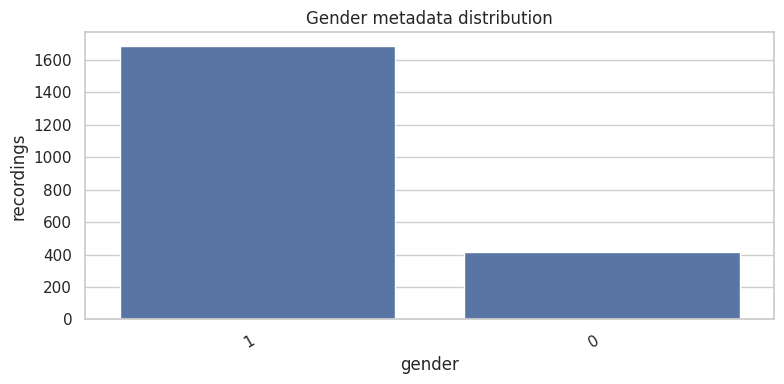

In [16]:
speaker_summary = None
if SPEAKER_COL:
    speaker_summary = (
        df.groupby(SPEAKER_COL, dropna=False)
          .agg(recording_count=(TRANSCRIPT_COL, "size"),
               mean_word_count=("word_count", "mean"),
               median_word_count=("word_count", "median"),
               mean_character_count=("character_count", "mean"))
          .reset_index()
          .sort_values("recording_count", ascending=False)
    )
    print("Unique speaker values:", df[SPEAKER_COL].nunique(dropna=True))
    display(speaker_summary.head(20))
    speaker_summary.to_csv(TABLES_DIR / "speaker_summary.csv", index=False)

    plt.figure(figsize=(12, 5))
    sns.histplot(speaker_summary["recording_count"], bins=25)
    plt.title("Distribution of recordings per speaker")
    plt.xlabel("Recordings per speaker")
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / "recordings_per_speaker.png", dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()
else:
    print("Speaker analysis skipped: no speaker identifier column was found.")

if GENDER_COL:
    gender_counts = df[GENDER_COL].fillna("Missing").astype(str).value_counts().rename_axis("gender").reset_index(name="recordings")
    display(gender_counts)
    gender_counts.to_csv(TABLES_DIR / "gender_distribution.csv", index=False)

    plt.figure(figsize=(8, 4))
    sns.barplot(data=gender_counts, x="gender", y="recordings")
    plt.title("Gender metadata distribution")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / "gender_distribution.png", dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()

    if SPEAKER_COL:
        speaker_gender = df.groupby(SPEAKER_COL)[GENDER_COL].nunique(dropna=True)
        inconsistent = speaker_gender[speaker_gender > 1]
        print("Speakers associated with multiple non-null gender values:", len(inconsistent))
else:
    print("Gender analysis skipped: no gender metadata column was found.")

## 13. Data-quality audit: metadata and transcripts

The audit flags potential issues for inspection. A flagged record is not automatically an error: for example, a short transcript may be valid. Thresholds are transparent and can be adjusted.

In [17]:
quality = pd.DataFrame(index=df.index)
quality["missing_transcript"] = df["transcript_original"].str.strip().eq("")
quality["duplicate_original_transcript"] = df["transcript_original"].duplicated(keep=False) & df["transcript_original"].str.strip().ne("")
quality["very_short_transcript_le_2_words"] = df["word_count"] <= 2
quality["very_long_transcript_gt_40_words"] = df["word_count"] > 40
quality["contains_replacement_character"] = df["transcript_original"].str.contains("\uFFFD", regex=False)
quality["contains_latin_letter"] = df["transcript_original"].str.contains(r"[A-Za-z]", regex=True)
quality["contains_control_character"] = df["transcript_original"].str.contains(r"[\x00-\x08\x0B\x0C\x0E-\x1F]", regex=True)

for col in df.columns:
    if col != "transcript_original" and col != "transcript_normalized" and col != "tokens":
        quality[f"missing_{col}"] = df[col].isna()

quality_summary = pd.DataFrame({
    "issue": quality.columns,
    "flagged_records": [int(quality[c].sum()) for c in quality.columns],
    "percent_of_dataset": [float(quality[c].mean() * 100) for c in quality.columns],
})
display(quality_summary)
quality_summary.to_csv(TABLES_DIR / "metadata_transcript_quality_audit.csv", index=False)

quality_flags = df[[c for c in [ID_COL, SPEAKER_COL, TRANSCRIPT_COL] if c is not None]].copy()
quality_flags = pd.concat([quality_flags, quality], axis=1)
quality_flags.to_csv(TABLES_DIR / "record_level_quality_flags.csv", index=False)

,issue,flagged_records,percent_of_dataset
0,missing_transcript,0,0.000000
1,duplicate_original_transcript,1534,72.908745
2,very_short_transcript_le_2_words,0,0.000000
3,very_long_transcript_gt_40_words,10,0.475285
4,contains_replacement_character,0,0.000000
5,contains_latin_letter,59,2.804183
6,contains_control_character,0,0.000000
7,missing_id,0,0.000000
8,missing_num_samples,0,0.000000
9,missing_path,0,0.000000


## 14. Select the representative audio sample

The sample size is capped at the available number of records. Random sampling is reproducible. Stratified sampling is attempted only when a speaker identifier exists; otherwise the notebook falls back to random sampling and explains why.

In [18]:
n_audio = min(AUDIO_SAMPLE_SIZE, len(dataset))
rng = np.random.default_rng(RANDOM_SEED)

def choose_audio_indices(frame, n, strategy="random"):
    if n >= len(frame):
        return np.arange(len(frame))
    if strategy == "stratified" and SPEAKER_COL:
        # Proportional allocation across speakers, then sample within each speaker.
        groups = frame.groupby(SPEAKER_COL, dropna=False).indices
        allocations = {key: len(idx) * n / len(frame) for key, idx in groups.items()}
        counts = {key: int(np.floor(value)) for key, value in allocations.items()}
        remainder = n - sum(counts.values())
        for key in sorted(allocations, key=lambda k: allocations[k] - counts[k], reverse=True)[:remainder]:
            counts[key] += 1
        chosen = []
        for key, idx in groups.items():
            take = min(counts[key], len(idx))
            if take:
                chosen.extend(rng.choice(np.asarray(idx), size=take, replace=False).tolist())
        return np.asarray(chosen[:n], dtype=int)
    if strategy == "stratified" and not SPEAKER_COL:
        print("Stratified sampling requested, but speaker metadata is unavailable. Using random sampling.")
    return rng.choice(len(frame), size=n, replace=False)

sample_indices = choose_audio_indices(
    df, n_audio,
    strategy="stratified" if AUDIO_SAMPLING_STRATEGY == "stratified" else "random"
)
sample_indices = np.sort(sample_indices)

print(f"Selected {len(sample_indices):,} audio examples.")
print("Sampling strategy:", AUDIO_SAMPLING_STRATEGY)

Selected 500 audio examples.
Sampling strategy: random


## 15. Decode audio and collect audio metadata

Only the selected sample is decoded. Audio decoding can take time. The resulting metadata table includes duration, sample rate, channel count, and basic amplitude statistics.

In [20]:
print(dataset.features[audio_column])
print(type(dataset[0][audio_column]))
print(dataset[0][audio_column])

Audio(sampling_rate=16000, decode=True, num_channels=None, stream_index=None)
<class 'datasets.features._torchcodec.AudioDecoder'>


In [23]:
print("Datasets version:", datasets.__version__)

print("\nAudio feature:")
print(dataset.features[audio_column])

print("\nAudio column type:")
print(type(dataset[0][audio_column]))

print("\nAudio payload:")
print(dataset[0][audio_column])

Datasets version: 5.1.0

Audio feature:
Audio(sampling_rate=16000, decode=True, num_channels=None, stream_index=None)

Audio column type:
<class 'datasets.features._torchcodec.AudioDecoder'>

Audio payload:


In [24]:
from datasets import Audio
import numpy as np

# Explicitly enable audio decoding
dataset = dataset.cast_column(
    audio_column,
    Audio(sampling_rate=None, decode=True)
)

# Inspect one example
example = dataset[0]
payload = example[audio_column]

print("Payload type:", type(payload))
print("Payload keys:", payload.keys() if isinstance(payload, dict) else "Not a dictionary")

Payload type: <class 'datasets.features._torchcodec.AudioDecoder'>
Payload keys: Not a dictionary


In [29]:
def get_audio_payload(example, audio_key="audio"):
    payload = example[audio_key]

    # Hugging Face datasets 5.x: AudioDecoder
    if hasattr(payload, "get_all_samples"):
        samples = payload.get_all_samples()

        arr = samples.data.cpu().numpy()
        sr = int(samples.sample_rate)

        return arr, sr

    # Compatibility with older datasets versions
    if isinstance(payload, dict):
        arr = np.asarray(payload["array"])
        sr = int(payload["sampling_rate"])
        return arr, sr

    raise TypeError(f"Unexpected audio payload type: {type(payload)}")


audio_records = []
audio_arrays = {}

if audio_column is None:
    raise ValueError("No audio column found in the dataset.")

for position, dataset_index in enumerate(sample_indices, start=1):
    example = dataset[int(dataset_index)]

    try:
        signal, sr = get_audio_payload(example, audio_column)

        if signal.ndim == 2:
            # Preserve channel count and create a mono signal
            # for scalar analysis.
            channel_count = signal.shape[0] if signal.shape[0] <= 8 else signal.shape[1]

            if signal.shape[0] <= 8:
                mono = signal.mean(axis=0)
            else:
                mono = signal.mean(axis=1)
        else:
            channel_count = 1
            mono = signal

        mono = np.asarray(mono, dtype=np.float32)

        duration = len(mono) / sr if sr else np.nan

        audio_arrays[int(dataset_index)] = (mono, sr)

        audio_records.append({
            "dataset_index": int(dataset_index),
            "sample_rate": sr,
            "channels": channel_count,
            "num_samples": len(mono),
            "duration_seconds": duration,
            "peak_amplitude": float(np.max(np.abs(mono))) if len(mono) else np.nan,
            "rms_amplitude": float(np.sqrt(np.mean(mono**2))) if len(mono) else np.nan,
            "is_silent_exact": bool(np.max(np.abs(mono)) == 0) if len(mono) else True,
        })

    except Exception as exc:
        audio_records.append({
            "dataset_index": int(dataset_index),
            "sample_rate": np.nan,
            "channels": np.nan,
            "num_samples": np.nan,
            "duration_seconds": np.nan,
            "peak_amplitude": np.nan,
            "rms_amplitude": np.nan,
            "is_silent_exact": np.nan,
            "decode_error": str(exc),
        })

    if position % 50 == 0 or position == len(sample_indices):
        print(f"Processed {position}/{len(sample_indices)}")

audio_df = pd.DataFrame(audio_records)

display(audio_df.head())

print("Successfully decoded:", len(audio_arrays))
print("Decode failures:", int(audio_df["duration_seconds"].isna().sum()))

audio_df.to_csv(TABLES_DIR / "audio_sample_metadata.csv", index=False)

Processed 50/500
Processed 100/500
Processed 150/500
Processed 200/500
Processed 250/500
Processed 300/500
Processed 350/500
Processed 400/500
Processed 450/500
Processed 500/500


,dataset_index,sample_rate,channels,num_samples,duration_seconds,peak_amplitude,rms_amplitude,is_silent_exact
0,10,16000,1,249600,15.60,0.256365,0.031237,False
1,12,16000,1,278400,17.40,0.237879,0.047636,False
2,13,16000,1,158400,9.90,0.283049,0.032871,False
3,18,16000,1,178560,11.16,0.502674,0.049252,False
4,28,16000,1,77760,4.86,0.285221,0.018014,False


Successfully decoded: 500
Decode failures: 0


## 16. Audio duration, sample rate, channels, and amplitude

These statistics describe the representative sample, not necessarily the entire split. Use the sample-size setting to increase or decrease coverage.

,count,mean,std,min,25%,50%,75%,max
duration_seconds,500.0,10.294560,4.017270,3.840000,7.440000,9.840000,12.060000,37.020000
sample_rate,500.0,16000.000000,0.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000
channels,500.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
peak_amplitude,500.0,0.291915,0.217394,0.010740,0.154148,0.243423,0.368414,1.000000
rms_amplitude,500.0,0.037172,0.033707,0.001425,0.017895,0.030639,0.043815,0.190092


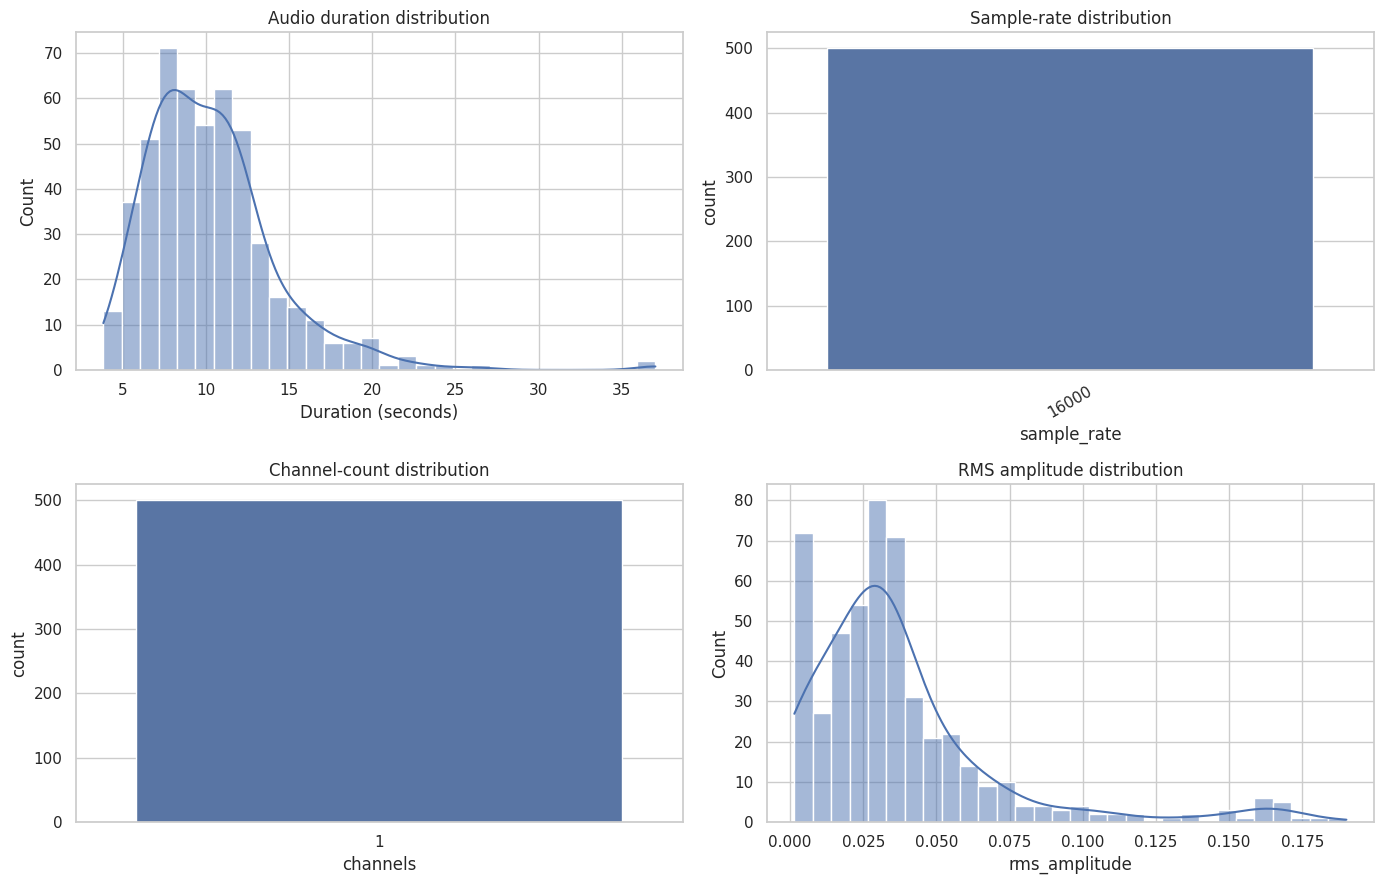

In [30]:
display(audio_df[["duration_seconds", "sample_rate", "channels", "peak_amplitude", "rms_amplitude"]].describe().T)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(audio_df["duration_seconds"].dropna(), bins=30, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Audio duration distribution")
axes[0, 0].set_xlabel("Duration (seconds)")

sns.countplot(data=audio_df.dropna(subset=["sample_rate"]), x="sample_rate", ax=axes[0, 1])
axes[0, 1].set_title("Sample-rate distribution")
axes[0, 1].tick_params(axis="x", rotation=30)

sns.countplot(data=audio_df.dropna(subset=["channels"]), x="channels", ax=axes[1, 0])
axes[1, 0].set_title("Channel-count distribution")

sns.histplot(audio_df["rms_amplitude"].dropna(), bins=30, kde=True, ax=axes[1, 1])
axes[1, 1].set_title("RMS amplitude distribution")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "audio_basic_distributions.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()

## 17. Waveform and spectrogram examples

The notebook displays a small number of representative recordings. Long clips are cropped for visualization only; the underlying audio is not modified.

### Audio example: dataset row 10 | 15.60 seconds | 16000 Hz

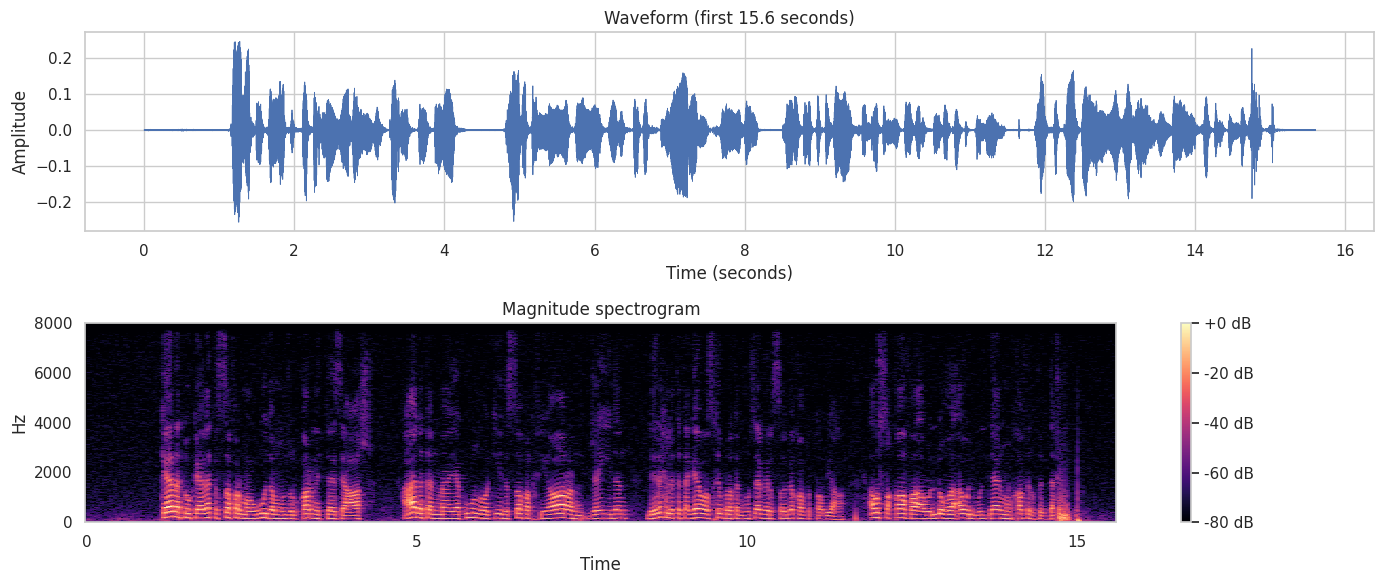

### Audio example: dataset row 12 | 17.40 seconds | 16000 Hz

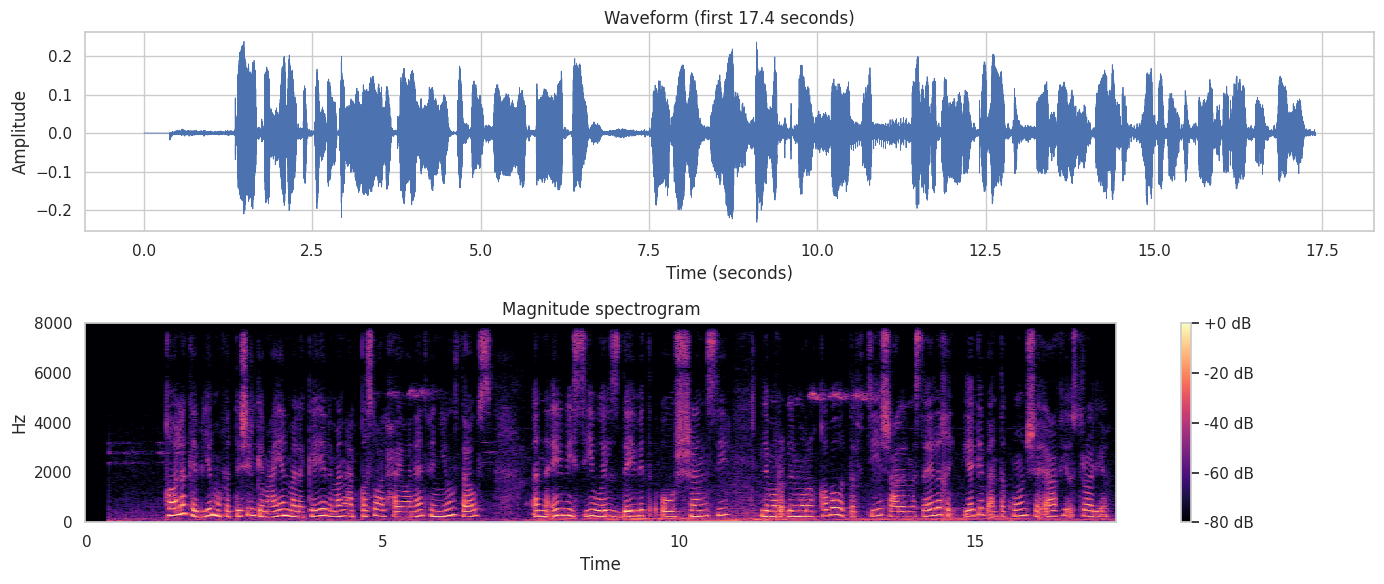

### Audio example: dataset row 13 | 9.90 seconds | 16000 Hz

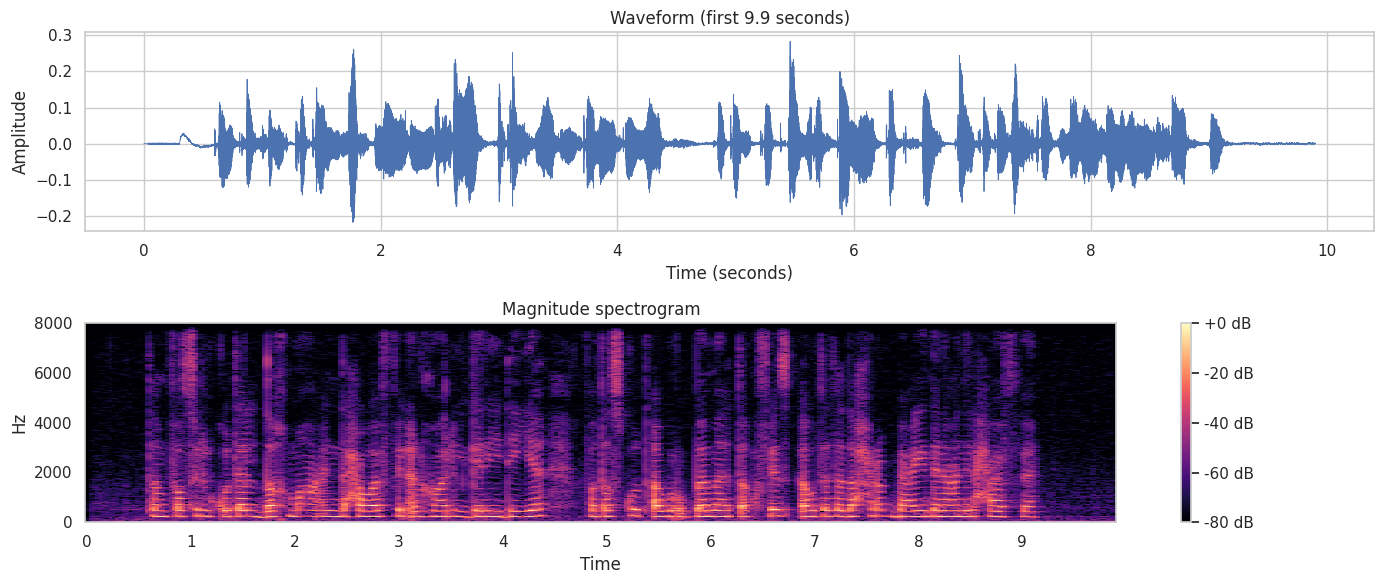

In [32]:
from IPython.display import Audio as IPyAudio

valid_audio_indices = [idx for idx in sample_indices if idx in audio_arrays]
example_indices = valid_audio_indices[:N_SPECTROGRAM_EXAMPLES]

for idx in example_indices:
    signal, sr = audio_arrays[int(idx)]
    duration = len(signal) / sr

    display(Markdown(
        f"### Audio example: dataset row {idx} | {duration:.2f} seconds | {sr} Hz"
    ))

    # Play audio using IPython's Audio
    display(IPyAudio(signal, rate=sr))

    crop = signal[:int(min(MAX_AUDIO_SECONDS_FOR_WAVEFORM, duration) * sr)]
    time_axis = np.arange(len(crop)) / sr

    fig, axes = plt.subplots(2, 1, figsize=(14, 6))

    axes[0].plot(time_axis, crop, linewidth=0.6)
    axes[0].set_title(f"Waveform (first {len(crop)/sr:.1f} seconds)")
    axes[0].set_xlabel("Time (seconds)")
    axes[0].set_ylabel("Amplitude")

    if len(crop) > 0:
        D = librosa.stft(crop)
        S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

        img = librosa.display.specshow(
            S_db,
            sr=sr,
            x_axis="time",
            y_axis="hz",
            ax=axes[1]
        )

        axes[1].set_title("Magnitude spectrogram")
        fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

    plt.tight_layout()

    plt.savefig(
        PLOTS_DIR / f"waveform_spectrogram_{idx}.png",
        dpi=FIGURE_DPI,
        bbox_inches="tight"
    )

    plt.show()

## 18. Silence and low-energy inspection

This is a simple frame-based estimate of low-energy regions. It is not a speech-activity detector and should not be interpreted as a definitive measure of silence or speech boundaries.

,count,mean,std,min,25%,50%,75%,max
duration_seconds,500.0,10.294560,4.017270,3.840000,7.440000,9.840000,12.060000,37.020000
rms_amplitude,500.0,0.037172,0.033707,0.001425,0.017895,0.030639,0.043815,0.190092
low_energy_fraction,500.0,0.081764,0.088784,0.000000,0.004986,0.042782,0.145505,0.462810


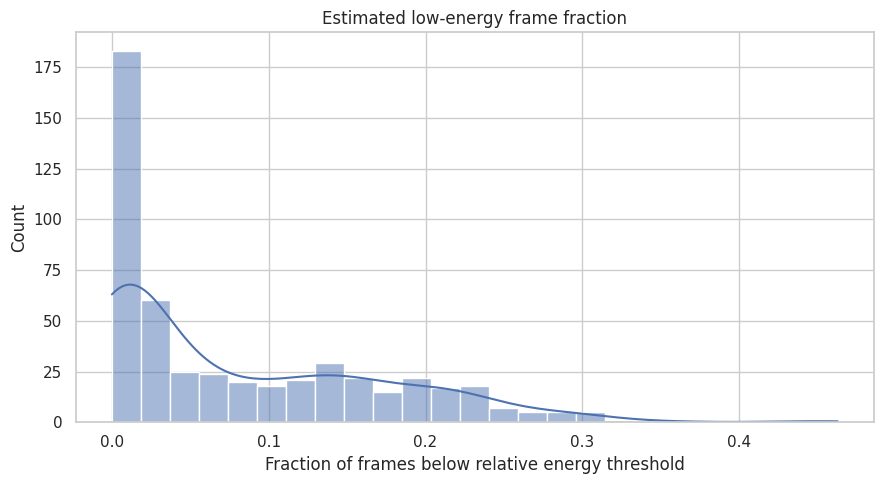

In [33]:
def low_energy_fraction(signal, frame_length=2048, hop_length=512, relative_threshold_db=-40):
    if len(signal) < frame_length:
        return np.nan
    rms = librosa.feature.rms(y=signal, frame_length=frame_length, hop_length=hop_length)[0]
    if len(rms) == 0 or np.max(rms) == 0:
        return 1.0
    threshold = np.max(rms) * (10 ** (relative_threshold_db / 20))
    return float(np.mean(rms < threshold))

low_energy = []
for idx, (signal, sr) in audio_arrays.items():
    low_energy.append({
        "dataset_index": idx,
        "low_energy_fraction": low_energy_fraction(signal),
    })

low_energy_df = pd.DataFrame(low_energy)
audio_df = audio_df.merge(low_energy_df, on="dataset_index", how="left")
audio_df.to_csv(TABLES_DIR / "audio_sample_metadata.csv", index=False)

display(audio_df[["duration_seconds", "rms_amplitude", "low_energy_fraction"]].describe().T)

plt.figure(figsize=(9, 5))
sns.histplot(audio_df["low_energy_fraction"].dropna(), bins=25, kde=True)
plt.title("Estimated low-energy frame fraction")
plt.xlabel("Fraction of frames below relative energy threshold")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "low_energy_fraction.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()

## 19. Combine audio metadata with transcript metadata

This section compares audio duration with transcript word and character counts. Because audio analysis uses a sample, these relationships are sample-based.

,count,mean,std,min,25%,50%,75%,max
duration_seconds,500.0,10.294560,4.017270,3.840000,7.440000,9.840000,12.060000,37.020000
word_count,500.0,17.922000,6.674805,5.000000,13.000000,17.000000,22.000000,42.000000
character_count,500.0,103.344000,39.024396,24.000000,75.000000,95.000000,125.000000,240.000000
words_per_second,500.0,1.769372,0.331812,0.857843,1.543036,1.761262,2.000000,2.688172
characters_per_second,500.0,10.171118,1.860984,4.943274,8.888052,10.261538,11.336134,16.183575


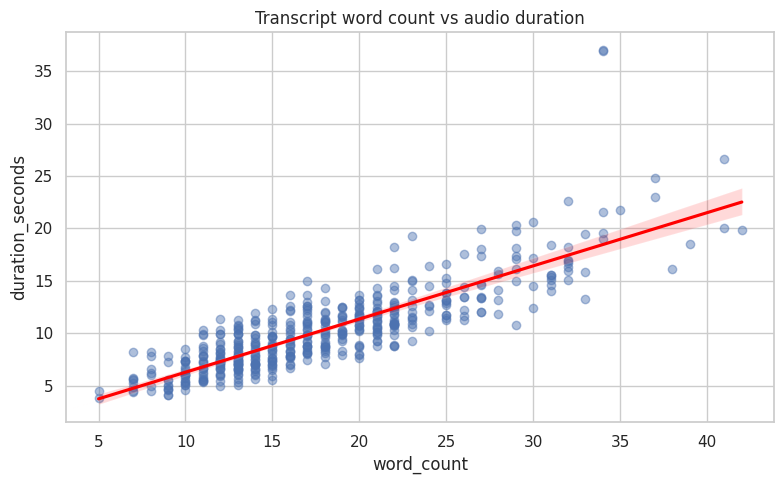

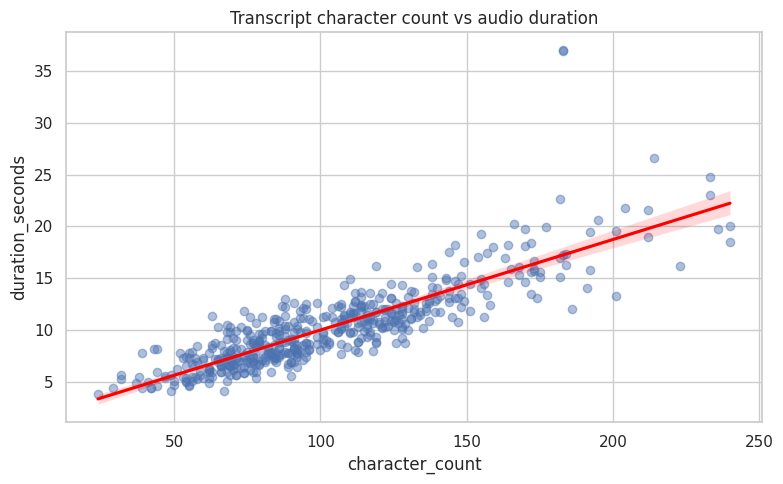

,text_measure,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,word_count,500,0.843347,2.007716e-136,0.851036,2.025734e-141
1,character_count,500,0.849053,4.181331e-140,0.865165,2.214189e-151
2,normalized_character_count,500,0.849500,2.123383e-140,0.866265,3.331224e-152


In [34]:
audio_text = audio_df.merge(
    df.reset_index().rename(columns={"index": "dataset_index"}),
    on="dataset_index",
    how="left",
    suffixes=("_audio", "")
)

audio_text["words_per_second"] = (
    audio_text["word_count"] / audio_text["duration_seconds"].replace(0, np.nan)
)
audio_text["characters_per_second"] = (
    audio_text["character_count"] / audio_text["duration_seconds"].replace(0, np.nan)
)

display(audio_text[[
    "duration_seconds", "word_count", "character_count",
    "words_per_second", "characters_per_second"
]].describe().T)

for x_col, title, filename in [
    ("word_count", "Transcript word count vs audio duration", "word_count_vs_duration.png"),
    ("character_count", "Transcript character count vs audio duration", "character_count_vs_duration.png"),
]:
    plt.figure(figsize=(8, 5))
    sns.regplot(data=audio_text, x=x_col, y="duration_seconds",
                scatter_kws={"alpha": 0.45}, line_kws={"color": "red"})
    plt.title(title)
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / filename, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()

corr_rows = []
for col in ["word_count", "character_count", "normalized_character_count"]:
    valid = audio_text[[col, "duration_seconds"]].dropna()
    if len(valid) >= 3:
        pearson = pearsonr(valid[col], valid["duration_seconds"])
        spearman = spearmanr(valid[col], valid["duration_seconds"])
        corr_rows.append({
            "text_measure": col,
            "n": len(valid),
            "pearson_r": pearson.statistic,
            "pearson_p": pearson.pvalue,
            "spearman_rho": spearman.statistic,
            "spearman_p": spearman.pvalue,
        })

correlation_table = pd.DataFrame(corr_rows)
display(correlation_table)
correlation_table.to_csv(TABLES_DIR / "text_audio_correlations.csv", index=False)

## 20. Speaking-rate exploration

Words per second is a rough transcript-to-duration ratio. It is not a phonetic speaking-rate measure: whitespace tokenization, clitics, punctuation, pauses, and recording boundaries all affect it. Treat it as a comparative exploratory feature.

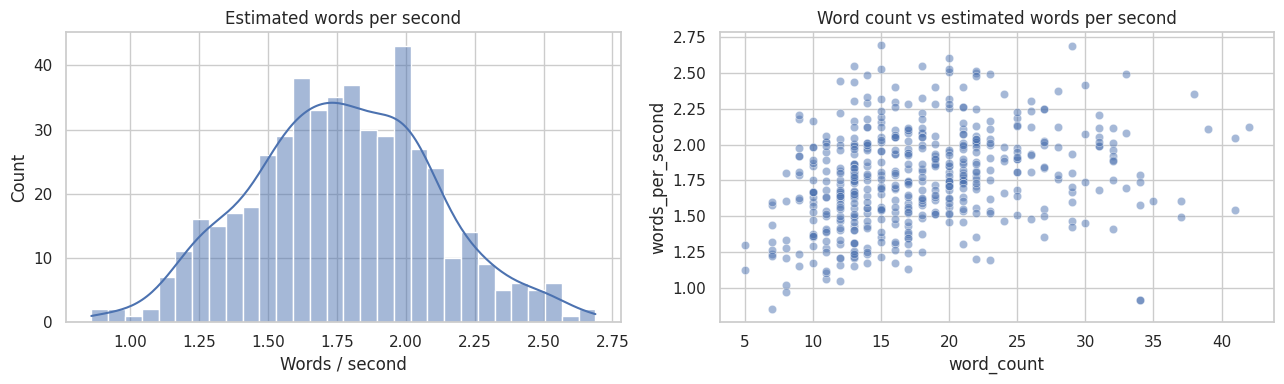

,words_per_second
count,500.000000
mean,1.769372
std,0.331812
min,0.857843
25%,1.543036
50%,1.761262
75%,2.000000
max,2.688172


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(audio_text["words_per_second"].replace([np.inf, -np.inf], np.nan).dropna(), bins=30, kde=True, ax=axes[0])
axes[0].set_title("Estimated words per second")
axes[0].set_xlabel("Words / second")

sns.scatterplot(data=audio_text, x="word_count", y="words_per_second", alpha=0.5, ax=axes[1])
axes[1].set_title("Word count vs estimated words per second")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "speaking_rate_exploration.png", dpi=FIGURE_DPI, bbox_inches="tight")
plt.show()

display(audio_text["words_per_second"].describe())

## 21. Audio quality and anomaly flags

These are heuristic flags for manual review, not objective quality labels. Thresholds are intentionally configurable and should be interpreted in the context of the dataset's recording protocol.

In [36]:
audio_quality = audio_df.copy()
audio_quality["missing_or_failed_decode"] = audio_quality["duration_seconds"].isna()
audio_quality["very_short_audio_lt_1s"] = audio_quality["duration_seconds"] < 1
audio_quality["long_audio_gt_20s"] = audio_quality["duration_seconds"] > 20
audio_quality["zero_or_near_zero_rms"] = audio_quality["rms_amplitude"] < 1e-4
audio_quality["unexpected_sample_rate"] = ~audio_quality["sample_rate"].isin([8000, 16000, 22050, 24000, 32000, 44100, 48000])

audio_quality_summary = pd.DataFrame({
    "issue": [c for c in audio_quality.columns if c not in audio_df.columns],
    "flagged_records": [int(audio_quality[c].fillna(False).sum()) for c in audio_quality.columns if c not in audio_df.columns],
})
display(audio_quality_summary)
audio_quality_summary.to_csv(TABLES_DIR / "audio_quality_audit.csv", index=False)

,issue,flagged_records
0,missing_or_failed_decode,0
1,very_short_audio_lt_1s,0
2,long_audio_gt_20s,11
3,zero_or_near_zero_rms,0
4,unexpected_sample_rate,0


## 22. Speaker-level audio comparisons

When speaker identifiers are available, compare sampled audio duration and estimated speaking rate across speakers. Since only a representative sample is decoded, small speaker sample counts should be treated cautiously.

In [37]:
if SPEAKER_COL:
    speaker_audio = audio_text.groupby(SPEAKER_COL).agg(
        sampled_recordings=("duration_seconds", "count"),
        mean_duration_seconds=("duration_seconds", "mean"),
        median_duration_seconds=("duration_seconds", "median"),
        mean_words_per_second=("words_per_second", "mean"),
    ).reset_index().sort_values("sampled_recordings", ascending=False)
    display(speaker_audio.head(20))
    speaker_audio.to_csv(TABLES_DIR / "speaker_audio_summary_sample.csv", index=False)

    eligible = speaker_audio[speaker_audio["sampled_recordings"] >= 3]
    if not eligible.empty:
        plt.figure(figsize=(12, 5))
        sns.scatterplot(data=eligible, x="mean_duration_seconds", y="mean_words_per_second",
                        size="sampled_recordings", sizes=(30, 250), alpha=0.7)
        plt.title("Speaker-level duration vs estimated speaking rate (sample)")
        plt.tight_layout()
        plt.savefig(PLOTS_DIR / "speaker_duration_vs_rate.png", dpi=FIGURE_DPI, bbox_inches="tight")
        plt.show()
else:
    print("Speaker-level audio comparison skipped: speaker metadata unavailable.")

Speaker-level audio comparison skipped: speaker metadata unavailable.


## 23. Final EDA summary

The following cell generates a concise, data-driven summary from the results produced in this runtime. It does not invent explanations for observed patterns. Interpretations that require listening, linguistic expertise, or additional metadata are explicitly left for follow-up.

In [38]:
def safe_stat(series, method):
    values = pd.to_numeric(series, errors="coerce").dropna()
    return float(getattr(values, method)()) if len(values) else np.nan

summary_lines = [
    "# Google FLEURS ar_eg train: EDA summary",
    "",
    "## Dataset coverage",
    f"- Dataset: `{DATASET_ID}`",
    f"- Configuration: `{CONFIG_NAME}`",
    f"- Split: `{SPLIT}`",
    f"- Training records loaded: **{len(df):,}**",
    f"- Metadata columns: **{len(df.columns)}**",
    "",
    "## Transcript overview",
    f"- Mean words per transcript: **{df['word_count'].mean():.2f}**",
    f"- Median words per transcript: **{df['word_count'].median():.2f}**",
    f"- Vocabulary size after light normalization: **{len(word_counter):,}**",
    f"- Total whitespace-tokenized tokens: **{len(all_tokens):,}**",
    "",
    "## Audio sample",
    f"- Requested sample size: **{AUDIO_SAMPLE_SIZE}**",
    f"- Successfully decoded audio examples: **{len(audio_arrays):,}**",
    f"- Median audio duration (sample): **{safe_stat(audio_df['duration_seconds'], 'median'):.2f} seconds**",
    f"- Mean audio duration (sample): **{safe_stat(audio_df['duration_seconds'], 'mean'):.2f} seconds**",
    "",
    "## Data quality",
    f"- Empty transcripts: **{int(df['transcript_original'].str.strip().eq('').sum()):,}**",
    f"- Duplicate non-empty original transcripts: **{int((df['transcript_original'].duplicated(keep=False) & df['transcript_original'].str.strip().ne('')).sum()):,}**",
    f"- Audio decode failures in sample: **{int(audio_df['duration_seconds'].isna().sum()):,}**",
    "",
    "## Interpretation notes",
    "- Audio statistics describe the selected sample, not necessarily every training recording.",
    "- Word counts use whitespace tokenization and do not constitute Arabic morphological segmentation.",
    "- Words-per-second is an approximate transcript-duration ratio, not a phonetic speaking-rate measurement.",
    "- Quality flags identify records for inspection; they do not prove that a record is invalid.",
    "",
    "## Recommended next steps",
    "- Listen to flagged audio examples and inspect their corresponding transcripts.",
    "- Review the dataset's intended transcript normalization and evaluation conventions before ASR scoring.",
    "- Use a held-out validation/test split for model evaluation; this EDA notebook analyzes only the training split.",
]
summary_text = "\n".join(summary_lines)
display(Markdown(summary_text))

with open(REPORT_DIR / "eda_summary.md", "w", encoding="utf-8") as f:
    f.write(summary_text)

# Google FLEURS ar_eg train: EDA summary

## Dataset coverage
- Dataset: `google/fleurs`
- Configuration: `ar_eg`
- Split: `train`
- Training records loaded: **2,104**
- Metadata columns: **16**

## Transcript overview
- Mean words per transcript: **18.14**
- Median words per transcript: **17.00**
- Vocabulary size after light normalization: **9,518**
- Total whitespace-tokenized tokens: **38,164**

## Audio sample
- Requested sample size: **500**
- Successfully decoded audio examples: **500**
- Median audio duration (sample): **9.84 seconds**
- Mean audio duration (sample): **10.29 seconds**

## Data quality
- Empty transcripts: **0**
- Duplicate non-empty original transcripts: **1,534**
- Audio decode failures in sample: **0**

## Interpretation notes
- Audio statistics describe the selected sample, not necessarily every training recording.
- Word counts use whitespace tokenization and do not constitute Arabic morphological segmentation.
- Words-per-second is an approximate transcript-duration ratio, not a phonetic speaking-rate measurement.
- Quality flags identify records for inspection; they do not prove that a record is invalid.

## Recommended next steps
- Listen to flagged audio examples and inspect their corresponding transcripts.
- Review the dataset's intended transcript normalization and evaluation conventions before ASR scoring.
- Use a held-out validation/test split for model evaluation; this EDA notebook analyzes only the training split.

## 24. Export tables and report artifacts

All tables are written as CSV files, plots as PNG files, and the generated Markdown summary as a report artifact. The output directory is configured in Section 0.

In [39]:
# Save a compact record-level transcript table (without audio arrays).
transcript_export_cols = [
    c for c in [
        ID_COL, SPEAKER_COL, GENDER_COL,
        "transcript_original", "transcript_normalized",
        "word_count", "character_count", "unique_word_count"
    ] if c is not None and c in df.columns
]
df[transcript_export_cols].to_csv(TABLES_DIR / "transcript_analysis_all_train.csv", index=False)

# Save a machine-readable run manifest.
manifest = {
    "dataset_id": DATASET_ID,
    "configuration": CONFIG_NAME,
    "split": SPLIT,
    "training_rows": int(len(df)),
    "audio_sample_requested": int(AUDIO_SAMPLE_SIZE),
    "audio_sample_decoded": int(len(audio_arrays)),
    "random_seed": int(RANDOM_SEED),
    "audio_sampling_strategy": AUDIO_SAMPLING_STRATEGY,
    "transcript_column": TRANSCRIPT_COL,
    "speaker_column": SPEAKER_COL,
    "gender_column": GENDER_COL,
}
with open(OUTPUT_DIR / "run_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)

print("Saved outputs:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(path)

Saved outputs:
/content/drive/MyDrive/FLEURS_ar_eg_EDA/plots/audio_basic_distributions.png
/content/drive/MyDrive/FLEURS_ar_eg_EDA/plots/character_count_vs_duration.png
/content/drive/MyDrive/FLEURS_ar_eg_EDA/plots/dataset_overview.png
/content/drive/MyDrive/FLEURS_ar_eg_EDA/plots/gender_distribution.png
/content/drive/MyDrive/FLEURS_ar_eg_EDA/plots/low_energy_fraction.png
/content/drive/MyDrive/FLEURS_ar_eg_EDA/plots/speaking_rate_exploration.png
/content/drive/MyDrive/FLEURS_ar_eg_EDA/plots/top_words.png
/content/drive/MyDrive/FLEURS_ar_eg_EDA/plots/transcript_length_distributions.png
/content/drive/MyDrive/FLEURS_ar_eg_EDA/plots/waveform_spectrogram_10.png
/content/drive/MyDrive/FLEURS_ar_eg_EDA/plots/waveform_spectrogram_12.png
/content/drive/MyDrive/FLEURS_ar_eg_EDA/plots/waveform_spectrogram_13.png
/content/drive/MyDrive/FLEURS_ar_eg_EDA/plots/word_count_vs_duration.png
/content/drive/MyDrive/FLEURS_ar_eg_EDA/reports/eda_summary.md
/content/drive/MyDrive/FLEURS_ar_eg_EDA/run_mani

## 25. Generate a standalone PDF report

This creates a readable PDF containing the generated summary, selected tables, and saved figures. It is separate from the notebook PDF export. The report includes the current run's actual results.

In [40]:
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image as RLImage,
    Table, TableStyle, PageBreak
)
from reportlab.lib.enums import TA_CENTER
from xml.sax.saxutils import escape

pdf_path = REPORT_DIR / "FLEURS_ar_eg_EDA_Report.pdf"
styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="ReportTitle", parent=styles["Title"], alignment=TA_CENTER,
    fontSize=20, leading=25, spaceAfter=14
))
styles.add(ParagraphStyle(
    name="SmallNote", parent=styles["BodyText"], fontSize=8, leading=11
))

story = [
    Paragraph("Google FLEURS Egyptian Arabic (ar_eg)", styles["ReportTitle"]),
    Paragraph("Exploratory Data Analysis | Training split", styles["Heading2"]),
    Spacer(1, 0.4*cm),
]

for line in summary_lines:
    if line.startswith("# "):
        continue
    elif line.startswith("## "):
        story.append(Spacer(1, 0.2*cm))
        story.append(Paragraph(escape(line[3:]), styles["Heading2"]))
    elif line.startswith("- "):
        story.append(Paragraph("• " + escape(line[2:]), styles["BodyText"]))
    elif line.strip():
        story.append(Paragraph(escape(line), styles["BodyText"]))
    else:
        story.append(Spacer(1, 0.12*cm))

story.append(PageBreak())
story.append(Paragraph("Selected visualizations", styles["Heading1"]))

for image_name in [
    "dataset_overview.png",
    "transcript_length_distributions.png",
    "top_words.png",
    "audio_basic_distributions.png",
    "low_energy_fraction.png",
    "word_count_vs_duration.png",
    "character_count_vs_duration.png",
    "speaking_rate_exploration.png",
]:
    image_path = PLOTS_DIR / image_name
    if image_path.exists():
        story.append(Paragraph(escape(image_name.replace("_", " ").replace(".png", "").title()), styles["Heading3"]))
        img = RLImage(str(image_path), width=16.5*cm, height=8.0*cm)
        img.hAlign = "CENTER"
        story.append(img)
        story.append(Spacer(1, 0.3*cm))

def add_csv_table(story_list, csv_path, title, max_rows=15):
    if not csv_path.exists():
        return
    data = pd.read_csv(csv_path).head(max_rows)
    if data.empty:
        return
    story_list.append(PageBreak())
    story_list.append(Paragraph(escape(title), styles["Heading2"]))
    table_data = [list(data.columns)] + data.astype(str).values.tolist()
    wrapped = [[Paragraph(escape(str(cell)), styles["SmallNote"]) for cell in row] for row in table_data]
    table = Table(wrapped, repeatRows=1, hAlign="LEFT")
    table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#243B53")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("GRID", (0, 0), (-1, -1), 0.35, colors.grey),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#F2F5F8")]),
        ("LEFTPADDING", (0, 0), (-1, -1), 4),
        ("RIGHTPADDING", (0, 0), (-1, -1), 4),
        ("TOPPADDING", (0, 0), (-1, -1), 4),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 4),
    ]))
    story_list.append(table)

add_csv_table(story, TABLES_DIR / "dataset_column_overview.csv", "Dataset columns and missingness")
add_csv_table(story, TABLES_DIR / "transcript_length_summary.csv", "Transcript length statistics")
add_csv_table(story, TABLES_DIR / "top_words.csv", "Most frequent tokens")
add_csv_table(story, TABLES_DIR / "text_audio_correlations.csv", "Text-audio correlations")
add_csv_table(story, TABLES_DIR / "metadata_transcript_quality_audit.csv", "Metadata and transcript quality audit")

doc = SimpleDocTemplate(
    str(pdf_path), pagesize=A4,
    rightMargin=1.6*cm, leftMargin=1.6*cm,
    topMargin=1.6*cm, bottomMargin=1.6*cm
)
doc.build(story)
print(f"PDF report generated: {pdf_path}")

PDF report generated: /content/drive/MyDrive/FLEURS_ar_eg_EDA/reports/FLEURS_ar_eg_EDA_Report.pdf


## 26. Export the executed notebook itself to PDF

The standalone PDF report above is designed for reading. To export the **entire executed notebook**, including code and outputs, use one of these Colab workflows:

### Option A: Colab print workflow
1. Run the notebook and save it.
2. In Colab, choose **File → Print** (or use the browser's print command).
3. Choose **Save as PDF** in the print dialog.
4. Check page orientation, margins, and background graphics before saving.

### Option B: Download `.ipynb` and export with Jupyter
Download the notebook from Colab, then run locally:

```bash
python -m pip install -U nbconvert
jupyter nbconvert --to webpdf --allow-chromium-download your_notebook.ipynb
```

`webpdf` may require a compatible Chromium installation. If it is unavailable, export HTML and use the browser's **Print → Save as PDF**:

```bash
jupyter nbconvert --to html your_notebook.ipynb
```

**Tip:** For a clean PDF, run all cells, clear unnecessary debug output, and avoid printing huge dataframes or audio arrays.

## 27. Final checklist

- [ ] Confirm the loaded configuration is `ar_eg` and split is `train`.
- [ ] Inspect the detected transcript, speaker, and gender columns.
- [ ] Confirm that original transcripts remain unchanged.
- [ ] Review the normalization examples.
- [ ] Confirm the audio sample size and sampling method.
- [ ] Listen to flagged or unusual audio examples.
- [ ] Review the quality-audit tables before deciding whether to exclude any records.
- [ ] Save the executed notebook.
- [ ] Generate the standalone PDF report.
- [ ] Export the full notebook to PDF if a code-inclusive PDF is required.

### Interpretation reminder

Exploratory patterns are not causal conclusions. The audio analyses describe the selected sample, while metadata and transcript statistics cover the full training split. Do not use this EDA alone to claim model performance or dataset suitability; those require a controlled ASR training and evaluation experiment.